# Brasil em Dados

## Análise exploratória dos dados

Este notebook explora a base integrada preparada no notebook
`01_preparacao_dos_dados.ipynb`.

Serão examinadas as distribuições das variáveis, estatísticas descritivas
e associações entre características socioeconômicas e indicadores
educacionais dos municípios.

As associações observadas serão tratadas como padrões estatísticos, e não
como evidência automática de causalidade.

## 1. Configuração e carregamento da base integrada

A base integrada será carregada da pasta `data/processed`. A análise
utilizará população e renda do Censo Demográfico de 2022 e indicadores
educacionais de 2023.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path("..")

DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
FIGURES = PROJECT_ROOT / "figures"

FIGURES.mkdir(parents=True, exist_ok=True)

arquivo_base_integrada = (
    DATA_PROCESSED / "brasil_em_dados_municipios.csv"
)

df_integrado = pd.read_csv(
    arquivo_base_integrada,
    encoding="utf-8-sig",
    dtype={"codigo_municipio": "Int64"}
)

print("Dimensões da base integrada:", df_integrado.shape)
display(df_integrado.head())

Dimensões da base integrada: (5569, 13)


,uf,codigo_municipio,municipio,REDE,taxa_aprovacao_2023,indicador_rendimento_2023,nota_matematica_2023,nota_portugues_2023,nota_media_2023,ideb_2023,populacao_2022,renda_domiciliar_per_capita_2022,observacao
0,RO,1100015,Alta Floresta D'Oeste,Pública,93.2,0.931733,254.11,246.21,5.005333,4.7,21494.0,1210.60,NaN
1,RO,1100023,Ariquemes,Pública,93.8,0.937832,251.95,251.99,5.065667,4.8,96833.0,1458.57,NaN
2,RO,1100031,Cabixi,Pública,99.7,0.997227,247.93,252.78,5.011833,5.0,5351.0,1323.79,NaN
3,RO,1100049,Cacoal,Pública,98.8,0.988228,247.61,249.67,4.954667,4.9,86887.0,1625.88,NaN
4,RO,1100056,Cerejeiras,Pública,96.7,0.966651,255.25,252.94,5.136500,5.0,15890.0,1554.33,NaN


## 2. Inspeção da base e valores ausentes

Antes das análises, serão conferidas as variáveis de interesse e a
quantidade de valores ausentes. A base integrada original será preservada;
a exclusão de registros ocorrerá apenas na cópia utilizada nas análises.

In [2]:
variaveis_analise = [
    "populacao_2022",
    "renda_domiciliar_per_capita_2022",
    "taxa_aprovacao_2023",
    "nota_matematica_2023",
    "nota_portugues_2023",
    "ideb_2023"
]

colunas_ausentes = [
    coluna
    for coluna in variaveis_analise
    if coluna not in df_integrado.columns
]

if colunas_ausentes:
    raise ValueError(
        f"Variáveis não encontradas na base integrada: {colunas_ausentes}"
    )

for coluna in variaveis_analise:
    df_integrado[coluna] = pd.to_numeric(
        df_integrado[coluna],
        errors="coerce"
    )

resumo_ausentes = pd.DataFrame({
    "quantidade_ausente": df_integrado[variaveis_analise].isna().sum(),
    "percentual_ausente": (
        100 * df_integrado[variaveis_analise].isna().mean()
    )
}).sort_values("percentual_ausente", ascending=False)

display(resumo_ausentes.round(2))

,quantidade_ausente,percentual_ausente
ideb_2023,187,3.36
nota_matematica_2023,186,3.34
nota_portugues_2023,186,3.34
taxa_aprovacao_2023,49,0.88
renda_domiciliar_per_capita_2022,1,0.02
populacao_2022,1,0.02


## 3. Preparação da base para análise

Será criada uma cópia contendo os registros completos nas variáveis
selecionadas. A base integrada original não será modificada.

A população também será transformada com `log(1 + população)` para
facilitar a visualização de sua distribuição, que costuma ser bastante
assimétrica entre municípios.

In [3]:
colunas_identificacao = [
    "uf",
    "codigo_municipio",
    "municipio"
]

df_analise = (
    df_integrado[colunas_identificacao + variaveis_analise]
    .dropna(subset=variaveis_analise)
    .copy()
)

df_analise["log_populacao_2022"] = np.log1p(
    df_analise["populacao_2022"]
)

registros_removidos = len(df_integrado) - len(df_analise)
percentual_removido = 100 * registros_removidos / len(df_integrado)

print("Registros na base integrada:", len(df_integrado))
print("Registros completos para esta análise:", len(df_analise))
print("Registros removidos por valores ausentes:", registros_removidos)
print(f"Percentual removido: {percentual_removido:.2f}%")

display(df_analise.head())

Registros na base integrada: 5569
Registros completos para esta análise: 5382
Registros removidos por valores ausentes: 187
Percentual removido: 3.36%


,uf,codigo_municipio,municipio,populacao_2022,renda_domiciliar_per_capita_2022,taxa_aprovacao_2023,nota_matematica_2023,nota_portugues_2023,ideb_2023,log_populacao_2022
0,RO,1100015,Alta Floresta D'Oeste,21494.0,1210.60,93.2,254.11,246.21,4.7,9.975576
1,RO,1100023,Ariquemes,96833.0,1458.57,93.8,251.95,251.99,4.8,11.480753
2,RO,1100031,Cabixi,5351.0,1323.79,99.7,247.93,252.78,5.0,8.585226
3,RO,1100049,Cacoal,86887.0,1625.88,98.8,247.61,249.67,4.9,11.372375
4,RO,1100056,Cerejeiras,15890.0,1554.33,96.7,255.25,252.94,5.0,9.673508


## 4. Análise univariada

A análise univariada examina cada variável individualmente. Serão
calculadas medidas descritivas e observadas as distribuições, a
assimetria e possíveis valores extremos.

Valores extremos identificados por regras estatísticas serão tratados
como pontos para investigação, não como erros automaticamente.

In [4]:
estatisticas = (
    df_analise[variaveis_analise]
    .describe()
    .T
)

estatisticas["assimetria"] = (
    df_analise[variaveis_analise]
    .skew()
)

display(estatisticas.round(2))

,count,mean,std,min,25%,50%,75%,max,assimetria
populacao_2022,5382.0,37499.51,210016.24,907.00,5437.50,11371.50,25048.50,11451999.00,36.57
renda_domiciliar_per_capita_2022,5382.0,1206.09,490.89,358.65,770.80,1174.41,1515.85,4299.91,0.87
taxa_aprovacao_2023,5382.0,93.31,6.63,57.20,89.90,95.30,98.60,100.00,-1.34
nota_matematica_2023,5382.0,252.52,19.10,190.20,239.04,252.00,264.40,404.89,0.83
nota_portugues_2023,5382.0,253.08,16.49,196.32,241.86,253.62,264.42,362.02,0.15
ideb_2023,5382.0,4.77,0.73,2.60,4.30,4.80,5.30,9.30,0.11


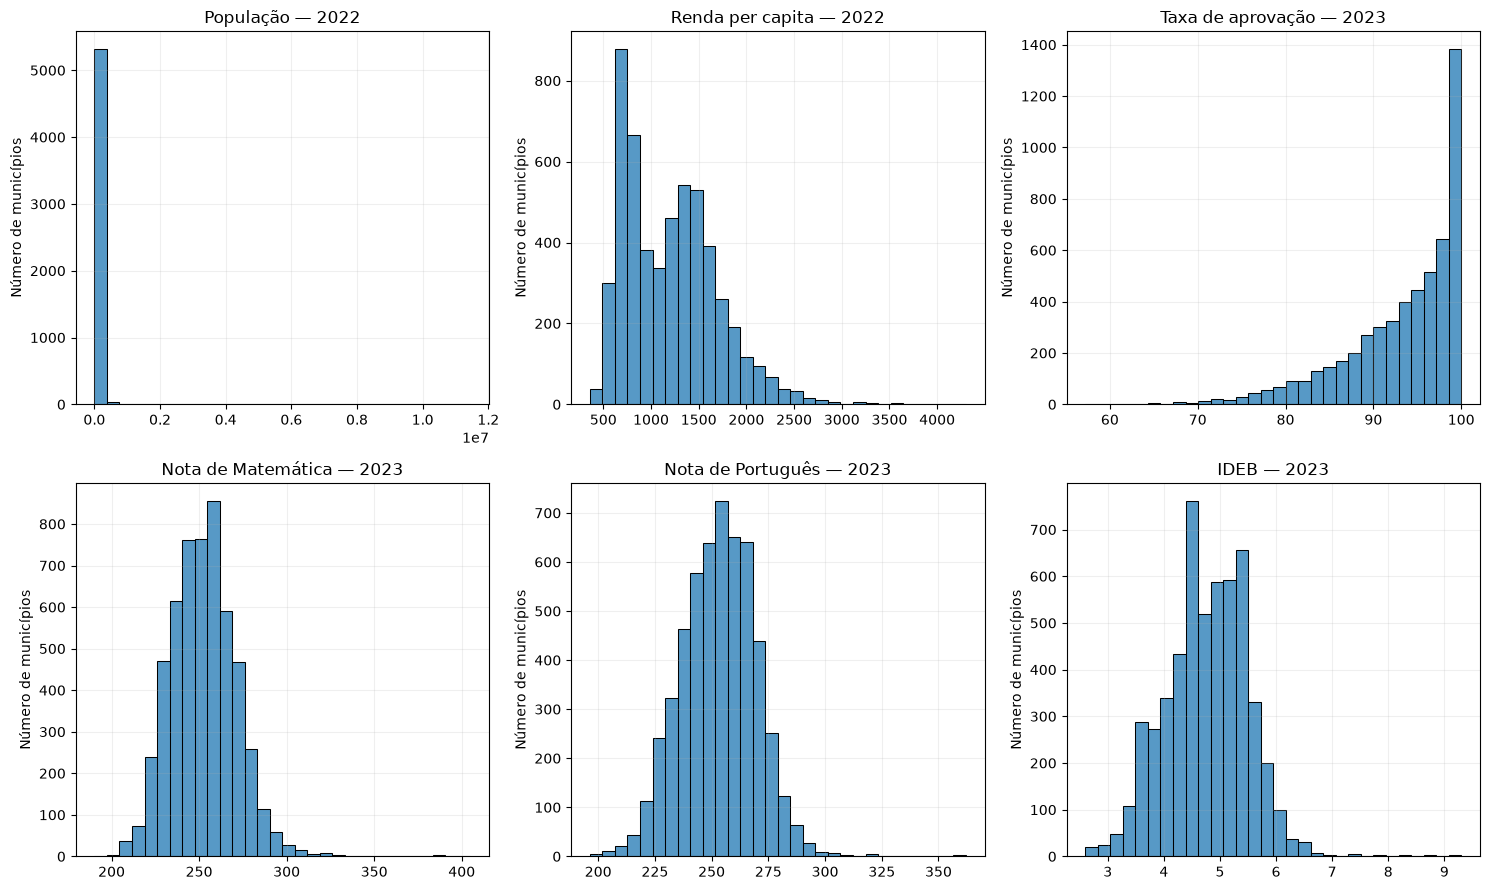

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

rotulos = {
    "populacao_2022": "População — 2022",
    "renda_domiciliar_per_capita_2022": "Renda per capita — 2022",
    "taxa_aprovacao_2023": "Taxa de aprovação — 2023",
    "nota_matematica_2023": "Nota de Matemática — 2023",
    "nota_portugues_2023": "Nota de Português — 2023",
    "ideb_2023": "IDEB — 2023"
}

for coluna, ax in zip(variaveis_analise, axes.flatten()):
    sns.histplot(
        data=df_analise,
        x=coluna,
        bins=30,
        ax=ax
    )
    ax.set_title(rotulos[coluna])
    ax.set_xlabel("")
    ax.set_ylabel("Número de municípios")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

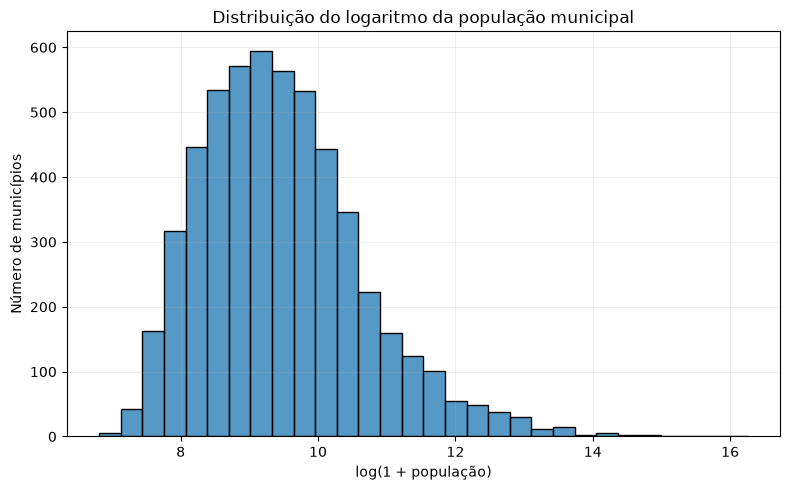

In [6]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_analise,
    x="log_populacao_2022",
    bins=30
)

plt.title("Distribuição do logaritmo da população municipal")
plt.xlabel("log(1 + população)")
plt.ylabel("Número de municípios")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [7]:
def resumo_outliers_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    intervalo_interquartil = q3 - q1

    limite_inferior = q1 - 1.5 * intervalo_interquartil
    limite_superior = q3 + 1.5 * intervalo_interquartil

    quantidade = (
        (serie < limite_inferior)
        | (serie > limite_superior)
    ).sum()

    return pd.Series({
        "limite_inferior": limite_inferior,
        "limite_superior": limite_superior,
        "quantidade_de_valores_extremos": quantidade,
        "percentual": 100 * quantidade / len(serie)
    })

resumo_extremos = pd.DataFrame({
    coluna: resumo_outliers_iqr(df_analise[coluna])
    for coluna in variaveis_analise
}).T

display(resumo_extremos.round(2))

,limite_inferior,limite_superior,quantidade_de_valores_extremos,percentual
populacao_2022,-23979.00,54465.00,595.0,11.06
renda_domiciliar_per_capita_2022,-346.79,2633.44,48.0,0.89
taxa_aprovacao_2023,76.85,111.65,149.0,2.77
nota_matematica_2023,201.02,302.42,53.0,0.98
nota_portugues_2023,208.03,298.25,41.0,0.76
ideb_2023,2.80,6.80,33.0,0.61


## 5. Análise multivariada

A análise multivariada examina associações entre duas ou mais variáveis.
Será utilizada a correlação de Spearman, que avalia associações
monotônicas e não exige que as variáveis tenham distribuição normal.

A correlação entre o IDEB e as notas de Matemática e Português deve ser
interpretada com cuidado, pois o desempenho nessas áreas participa da
composição do indicador.

In [8]:
variaveis_correlacao = [
    "log_populacao_2022",
    "renda_domiciliar_per_capita_2022",
    "taxa_aprovacao_2023",
    "nota_matematica_2023",
    "nota_portugues_2023",
    "ideb_2023"
]

nomes_variaveis = {
    "log_populacao_2022": "Log da população",
    "renda_domiciliar_per_capita_2022": "Renda per capita",
    "taxa_aprovacao_2023": "Aprovação",
    "nota_matematica_2023": "Matemática",
    "nota_portugues_2023": "Português",
    "ideb_2023": "IDEB"
}

correlacoes = (
    df_analise[variaveis_correlacao]
    .rename(columns=nomes_variaveis)
    .corr(method="spearman")
)

display(correlacoes.round(2))

,Log da população,Renda per capita,Aprovação,Matemática,Português,IDEB
Log da população,1.00,0.02,-0.14,-0.09,-0.01,-0.08
Renda per capita,0.02,1.00,0.22,0.52,0.52,0.49
Aprovação,-0.14,0.22,1.00,0.41,0.38,0.71
Matemática,-0.09,0.52,0.41,1.00,0.92,0.90
Português,-0.01,0.52,0.38,0.92,1.00,0.88
IDEB,-0.08,0.49,0.71,0.90,0.88,1.00


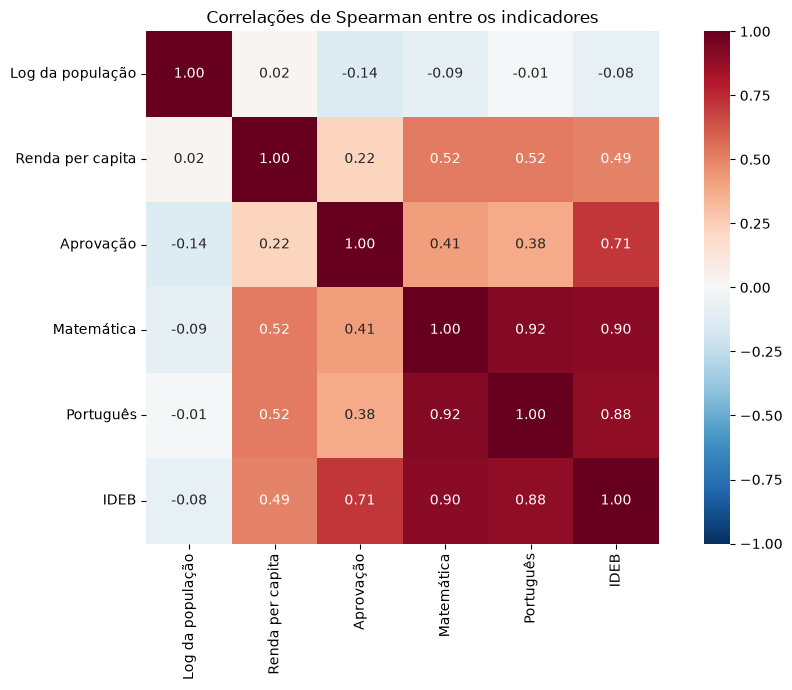

In [9]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlacoes,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlações de Spearman entre os indicadores")
plt.tight_layout()
plt.show()

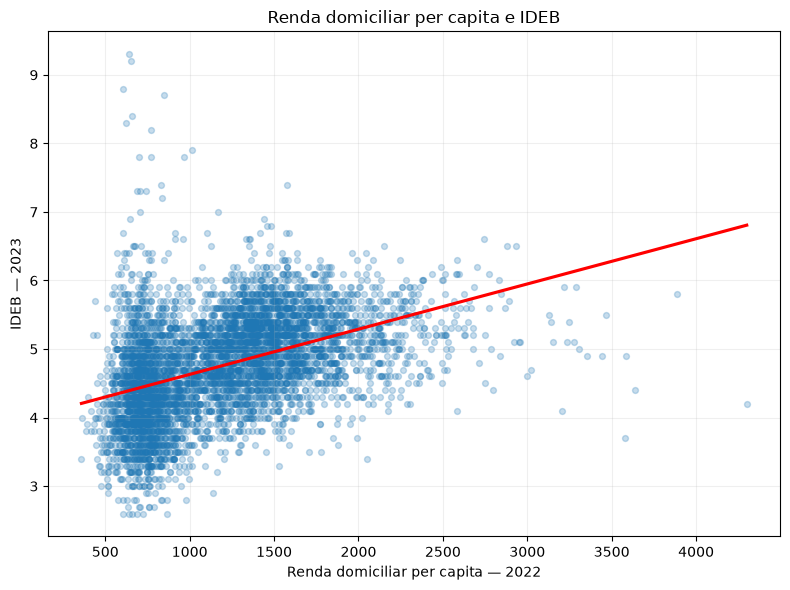

In [10]:
plt.figure(figsize=(8, 6))

sns.regplot(
    data=df_analise,
    x="renda_domiciliar_per_capita_2022",
    y="ideb_2023",
    ci=None,
    scatter_kws={"alpha": 0.25, "s": 18},
    line_kws={"color": "red"}
)

plt.xlabel("Renda domiciliar per capita — 2022")
plt.ylabel("IDEB — 2023")
plt.title("Renda domiciliar per capita e IDEB")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

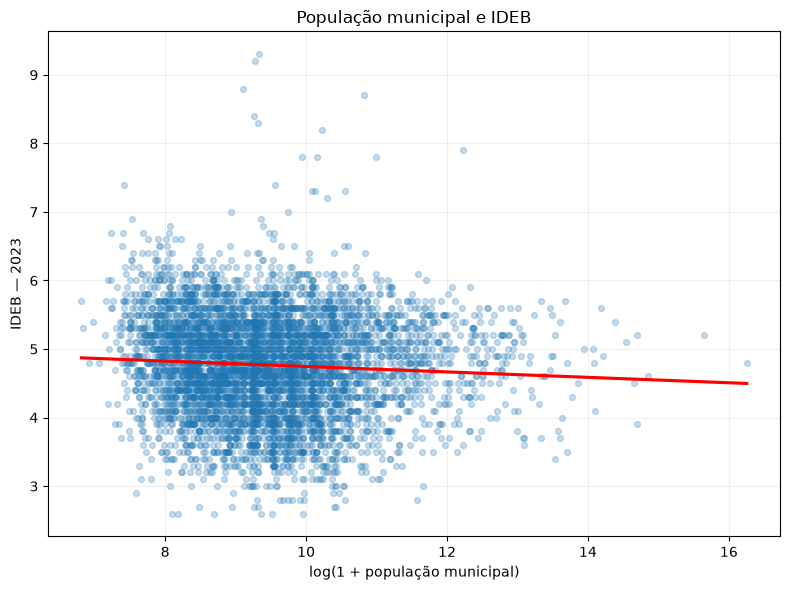

In [11]:
plt.figure(figsize=(8, 6))

sns.regplot(
    data=df_analise,
    x="log_populacao_2022",
    y="ideb_2023",
    ci=None,
    scatter_kws={"alpha": 0.25, "s": 18},
    line_kws={"color": "red"}
)

plt.xlabel("log(1 + população municipal)")
plt.ylabel("IDEB — 2023")
plt.title("População municipal e IDEB")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [12]:
df_analise["faixa_renda"] = pd.qcut(
    df_analise["renda_domiciliar_per_capita_2022"],
    q=4,
    labels=[
        "Q1 — menores rendas",
        "Q2 — renda média-baixa",
        "Q3 — renda média-alta",
        "Q4 — maiores rendas"
    ]
)

resumo_faixas_renda = (
    df_analise
    .groupby("faixa_renda", observed=True)
    .agg(
        numero_municipios=("codigo_municipio", "count"),
        renda_mediana=(
            "renda_domiciliar_per_capita_2022",
            "median"
        ),
        ideb_medio=("ideb_2023", "mean"),
        ideb_mediano=("ideb_2023", "median")
    )
    .round(2)
)

display(resumo_faixas_renda)

,numero_municipios,renda_mediana,ideb_medio,ideb_mediano
faixa_renda,,,,
Q1 — menores rendas,1346,677.32,4.35,4.3
Q2 — renda média-baixa,1345,923.24,4.53,4.5
Q3 — renda média-alta,1345,1353.73,5.01,5.0
Q4 — maiores rendas,1346,1765.16,5.17,5.2


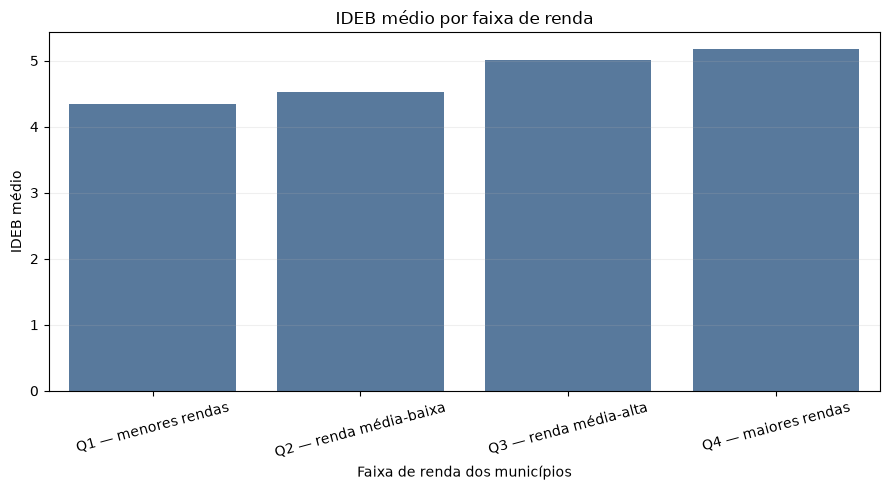

In [13]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=resumo_faixas_renda.reset_index(),
    x="faixa_renda",
    y="ideb_medio",
    color="#4C78A8"
)

plt.xlabel("Faixa de renda dos municípios")
plt.ylabel("IDEB médio")
plt.title("IDEB médio por faixa de renda")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 6. Síntese da análise exploratória

A população apresentou a maior assimetria entre as variáveis. A regra do
intervalo interquartil sinalizou possíveis valores extremos, sobretudo na
população, mas eles foram mantidos, pois não são automaticamente erros.

A renda domiciliar per capita apresentou associação positiva moderada com
o IDEB (Spearman = 0,49), enquanto a população teve associação muito fraca
e negativa (-0,08). O IDEB médio aumentou de 4,35 no quartil de menor renda
para 5,17 no quartil de maior renda.

As associações do IDEB com Matemática, Português e aprovação devem ser
interpretadas com cautela, pois esses indicadores estão relacionados à
composição dos resultados educacionais. Os resultados descrevem padrões
municipais, mas não demonstram causalidade.